# Stochastic weight averaging

Average late SGD checkpoints and measure train and test error at the averaged point.

Use a fixed learning rate to keep iterates moving around a least-squares optimum. Save late epoch checkpoints, average them in parameter space and compare against the final iterate on fresh noisy observations. A convex two-weight problem makes the loss surface visible.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Construct the weights and test their behaviour

Inspect the arrays and the reference output. Each check describes a specific property of the constructed model.

late checkpoints 28 test MSE final and averaged [0.3576 0.3621]


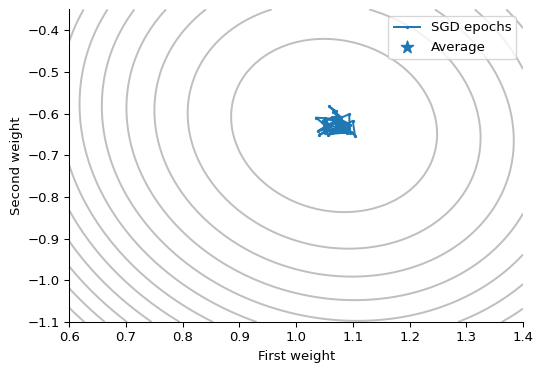

In [2]:
rng = np.random.default_rng(73)
X = rng.normal(size=(140, 2))
wstar = np.array([1.1, -0.7])
y = X @ wstar + rng.normal(0, 0.6, len(X))
T = rng.normal(size=(400, 2))
yt = T @ wstar + rng.normal(0, 0.6, len(T))
w = np.zeros(2)
path = []
for epoch in range(48):
    for group in np.array_split(rng.permutation(len(X)), 10):
        w -= 0.12 * (X[group].T @ (X[group] @ w - y[group])) / len(group)
    path.append(w.copy())
path = np.array(path)
avg = path[20:].mean(0)
scores = [np.mean((T @ p - yt) ** 2) for p in [w, avg]]
print("late checkpoints", len(path[20:]), "test MSE final and averaged", np.round(scores, 4))
gridx, gridy = np.meshgrid(np.linspace(0.6, 1.4, 65), np.linspace(-1.1, -0.35, 65))
grid = np.stack((gridx, gridy), axis=-1)
loss = np.mean((np.einsum("ij,abj->abi", X, grid) - y) ** 2, axis=-1)
fig, ax = plt.subplots(figsize=(5.6, 3.8), constrained_layout=True)
ax.contour(gridx, gridy, loss, levels=15, colors="0.75")
ax.plot(*path[2:].T, ".-", ms=3, label="SGD epochs")
ax.scatter(*avg, marker="*", s=95, label="Average")
ax.set(xlabel="First weight", ylabel="Second weight")
ax.legend()
plt.show()

## Interpreting the result

The average lies inside the late trajectory. Whether its test error improves is an empirical outcome, and the single run gives no general performance guarantee.

## Exercise

Change the averaging start epoch and plot held-out error against the number of checkpoints.

## References

[Izmailov et al., Averaging Weights Leads to Wider Optima (2018)](https://arxiv.org/abs/1803.05407)